# Training notebook v2: every model from scratch (Colab GPU)

This notebook retrains the full list of models in a fixed order. It makes **no champion decisions**: each cell names its runs directly. Comparing models happens afterwards in the evaluation notebook, with `RUNS` pointed at `ladder_runs_v2`.

**Before the first run**
1. In Drive, rename the old `amazon_caches/ladder_runs` folder to `ladder_runs_v1`. Keep `amazon_tif_128` and `amazon_tif_256` (the caches) as they are.
2. Runtime → Change runtime type → **GPU (A100, or L4) with High-RAM**.
3. Run sections 1–4 once per session. Then run the model cells in order, or section 6 to run everything at once.

**What is saved for every run** (in `amazon_caches/ladder_runs_v2/`, on Drive, written as soon as the run finishes):
| File | Contents |
|---|---|
| `<name>_probs.npz` | Validation and test probabilities + true labels (used by the evaluation notebook) |
| `<name>_history.json` | Per-epoch training loss, validation macro F2 @0.2, resolution and seconds |
| `<name>_settings.json` | All settings, parameter count, time per epoch, prediction speed, peak GPU memory, best epoch |
| `<name>.pt` | Weights of the best epoch |

**Safe to rerun:** a run whose `_probs.npz` already exists is skipped. If Colab disconnects, reconnect, run sections 1–4 again and rerun the cell you were on. 256 px and progressive runs save a checkpoint every epoch and resume from it.

**Shared setup for all models:** weather = one 4-class prediction (softmax); the 13 land labels = sigmoid + BCE with pos_weight and oversampling of rare-label chips (unless `balance=False`); AdamW + OneCycle, 14 epochs, batch 128, 8-view flip/rotation augmentation and test-time augmentation; best epoch picked on validation macro F2. The one training chip without a weather label (`train_24448`) is dropped. All models use 128 px input unless the cell says otherwise.

**Estimated time on an A100:** about 2–2.5 hours for all 32 runs, plus ~10–15 min to copy the 256 px cache the first time a 256 px or progressive run starts.

## 1. Settings, Drive and the 128 px cache

In [ ]:
import os, sys, json, shutil, subprocess

DRIVE_DIR = "/content/drive/MyDrive/amazon_caches"   # where the caches live on Drive
RUNS      = f"{DRIVE_DIR}/ladder_runs_v2"            # NEW output folder for this notebook (v1 results stay untouched)
ROOT128   = "/content/amazon_tif_128"                 # local copies of the caches (local disk is much faster than Drive)
ROOT256   = "/content/amazon_tif_256"

from google.colab import drive
drive.mount("/content/drive")
os.makedirs(RUNS, exist_ok=True)

def restore(root):
    """Copy a cache folder from Drive to Colab's local disk, unless it is already there."""
    if not os.path.exists(f"{root}/cache/X.npy"):
        shutil.rmtree(root, ignore_errors=True)             # remove a half-finished copy, if any
        src = f"{DRIVE_DIR}/{os.path.basename(root)}"
        print("copying", src, "->", root, "(a few minutes)")
        shutil.copytree(src, root, ignore=shutil.ignore_patterns("runs", "figs"))
    print(root, "ready")

restore(ROOT128)                                          # every model needs the 128 px cache
!nvidia-smi --query-gpu=name,memory.total --format=csv
!free -h | head -2

Mounted at /content/drive
copying /content/drive/MyDrive/amazon_caches/amazon_tif_128 -> /content/amazon_tif_128 (a few minutes)
/content/amazon_tif_128 ready
name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB
               total        used        free      shared  buff/cache   available
Mem:           167Gi       3.3Gi       131Gi       2.4Mi        34Gi       163Gi


## 2. Install TorchGeo (needed for the Sentinel-2 weights, about 1 minute)

In [ ]:
!pip -q install torchgeo

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 3. Write the training script
This cell saves the full training code as `run_ladder.py` in the Colab session. Read through it to see how the data are loaded, how each model is built and how training works; each part is commented. Nothing trains yet.

In [ ]:
%%writefile run_ladder.py
#!/usr/bin/env python3
"""
run_ladder.py: trains the model-development ladder for the Amazon deforestation project.

Every run is described by a small settings dict (architecture, pretraining, input channels,
imbalance handling, pooling, resolution schedule, seed). The run's NAME is built from its
settings, so the same settings always map to the same name. That makes the script:
  * resumable: a run whose predictions already exist in the runs folder is skipped, and long
    (256 px / progressive) runs resume from their last finished epoch after a disconnect;
  * easy to chain: a later stage can say "the champion, but without imbalance handling" and
    get a new, uniquely named run.

All models treat WEATHER as one 4-class prediction (softmax + cross-entropy) and the 13 LAND
labels as independent yes/no outputs (sigmoid + binary cross-entropy).

Outputs per run (written to --runs, e.g. a Google Drive folder):
  <name>_probs.npz      validation/test probabilities (17 columns) + true labels + chip indices
  <name>.pt             best model weights
  <name>_history.json   loss and validation score per epoch
  <name>_settings.json  settings + efficiency numbers (parameters, time, GPU memory)

Usage:
  python run_ladder.py --root128 /content/amazon_tif_128 --root256 /content/amazon_tif_256 \
                       --runs /content/drive/MyDrive/amazon_caches/ladder_runs --plan plan.json
  plan.json = {"runs": [ {settings...}, {settings...} ]}
"""
import argparse, copy, json, math, os, shutil, sys, time, traceback
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

# ====================================================================== settings
DEFAULTS = dict(
    arch="resnet18",        # scratch | resnet18 | resnet34 | resnet50 | efficientnet_b0
    pretrain="imagenet",    # none | imagenet | sentinel2
    chans=[0, 1, 2],        # cache channels: 0=R 1=G 2=B 3=NIR 4=NDVI
    balance=True,           # pos_weight in the land loss + oversampling of rare-label chips
    pool="avg",             # avg = global average pooling | avgmax = concatenated average + max
    res="128",              # 128 | 256 | prog (train at 128, last `hi_epochs` epochs at 256)
    hi_epochs=3,            # full-resolution epochs for res="prog"
    epochs=14,
    batch=128,
    lr=None,                # None = 3e-3 for the scratch CNN, 1e-3 for pretrained/large networks
    seed=42,
    s2_weights="all",       # Sentinel-2 weights: "all" (13-band model; keeps the R, G, B, NIR slices) | "rgb" (3-band model)
    norm="zscore",          # input scaling: "zscore" (each band to mean 0, std 1) | "s2match" (see S2_STATS)
)
# Mean and std of Sentinel-2 bands in the SSL4EO-S12 data the TorchGeo weights were trained on (raw values;
# the network saw them divided by 10,000). norm="s2match" rescales each of our bands to these statistics,
# so a Sentinel-2-pretrained network sees inputs on the scale it was trained on.
S2_STATS = {0: (1373.1, 1144.9),   # R   = B4
            1: (1322.3, 878.7),    # G   = B3
            2: (1397.6, 854.3),    # B   = B2
            3: (2318.7, 1249.5)}   # NIR = B8
CH_NAMES = ["R", "G", "B", "NIR", "NDVI"]
WEATHER = ["clear", "partly_cloudy", "haze", "cloudy"]
DEFOR = ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine"]


def full_settings(s):
    """Fill in defaults so every run's settings file is complete."""
    out = copy.deepcopy(DEFAULTS)
    out.update({k: v for k, v in s.items() if k != "name"})
    if out["arch"] == "scratch":
        out["pretrain"] = "none"
    if out["lr"] is None:
        out["lr"] = 3e-3 if out["arch"] == "scratch" else 1e-3
    out["chans"] = list(out["chans"])
    return out


def run_name(s):
    """Unique, readable run name built from the settings (defaults are left out)."""
    arch = {"scratch": "scratch", "resnet18": "r18", "resnet34": "r34", "resnet50": "r50",
            "efficientnet_b0": "effb0"}[s["arch"]]
    pre = {"none": "none", "imagenet": "imnet", "sentinel2": "s2"}[s["pretrain"]]
    ch = {(0, 1, 2): "rgb", (0, 1, 2, 3): "rgbn", (0, 1, 2, 3, 4): "rgbnv"}.get(
        tuple(s["chans"]), "c" + "".join(map(str, s["chans"])))
    parts = [arch, pre, ch]
    if not s["balance"]:
        parts.append("nobal")
    if s["pool"] != "avg":
        parts.append(s["pool"])
    if s["res"] != "128":
        parts.append(s["res"] if s["res"] != "prog" else f"prog{s['hi_epochs']}")
    if s["epochs"] != DEFAULTS["epochs"]:
        parts.append(f"e{s['epochs']}")
    if s["pretrain"] == "sentinel2" and s["s2_weights"] != "all":
        parts.append("s2" + s["s2_weights"])
    if s.get("norm", "zscore") != "zscore":
        parts.append("s2norm" if s["norm"] == "s2match" else s["norm"])
    default_lr = 3e-3 if s["arch"] == "scratch" else 1e-3           # non-default learning rates go in the name
    if s.get("lr") is not None and abs(s["lr"] - default_lr) > 1e-12:
        parts.append(f"lr{s['lr']:g}")
    if s["seed"] != 42:
        parts.append(f"s{s['seed']}")
    return "_".join(parts)


# ====================================================================== data
def mem_available_gb():
    try:
        for line in open("/proc/meminfo"):
            if line.startswith("MemAvailable"):
                return int(line.split()[1]) / 1e6
    except OSError:
        pass
    return 8.0


class Split:
    """The chips of one split (train/val/test) at one resolution.
    Loaded into RAM when it fits comfortably; otherwise read from the memory-mapped cache
    batch by batch (only the rows a batch needs are read from disk)."""

    def __init__(self, xmm, idx, chans, label):
        self.idx, self.chans = np.asarray(idx), list(chans)
        need_gb = len(idx) * len(chans) * xmm.shape[2] * xmm.shape[3] * 2 / 1e9
        self.in_ram = need_gb < 0.5 * mem_available_gb() and os.environ.get("LADDER_FORCE_DISK") != "1"
        if self.in_ram:
            arr = np.empty((len(idx), len(chans), xmm.shape[2], xmm.shape[3]), dtype=np.float16)
            for s in range(0, len(idx), 1000):                     # chunked, so RAM never spikes
                arr[s:s + 1000] = np.asarray(xmm[self.idx[s:s + 1000]])[:, self.chans]
            self.data = torch.from_numpy(arr)
        else:
            self.xmm = xmm
        print(f"  {label}: {len(idx)} chips at {xmm.shape[2]} px, {need_gb:.1f} GB -> "
              f"{'RAM' if self.in_ram else 'read from disk per batch'}", flush=True)

    def __len__(self):
        return len(self.idx)

    def get(self, pos):
        """pos = positions within this split (numpy array). Returns a float16 CPU tensor."""
        if self.in_ram:
            return self.data[torch.as_tensor(pos)]
        order = np.argsort(pos)                                    # read the cache in file order
        rows = np.asarray(self.xmm[self.idx[pos[order]]])[:, self.chans]
        out = np.empty_like(rows)
        out[order] = rows                                          # put back in the requested order
        return torch.from_numpy(out)


# ====================================================================== models
class Net(nn.Module):
    """Backbone (convolutional features) + pooling + one linear output layer (17 outputs)."""

    def __init__(self, features, n_feat, pool, dropout, n_out):
        super().__init__()
        self.features, self.pool = features, pool
        self.drop = nn.Dropout(dropout) if dropout else nn.Identity()
        self.fc = nn.Linear(n_feat * (2 if pool == "avgmax" else 1), n_out)

    def forward(self, x):
        f = self.features(x)                                       # (N, C, h, w) feature maps
        if self.pool == "avgmax":                                  # "how much" + "is it anywhere"
            v = torch.cat([f.mean((2, 3)), f.amax((2, 3))], 1)
        else:                                                      # global average pooling
            v = f.mean((2, 3))
        return self.fc(self.drop(v))


def scratch_features(c_in):
    """The project's original scratch CNN: 4 VGG-style blocks, 32 -> 256 channels."""
    def block(i, o):
        return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                             nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                             nn.MaxPool2d(2))
    return nn.Sequential(block(c_in, 32), block(32, 64), block(64, 128), block(128, 256)), 256


def new_first_conv(old, w_new):
    """A copy of conv layer `old` with a different number of input channels and weights w_new."""
    conv = nn.Conv2d(w_new.shape[1], old.out_channels, old.kernel_size, old.stride, old.padding,
                     bias=old.bias is not None)
    with torch.no_grad():
        conv.weight.copy_(w_new)
        if old.bias is not None:
            conv.bias.copy_(old.bias)
    return conv


def imagenet_first_weights(w_rgb, chans):
    """ImageNet filters for R, G, B; each extra channel (NIR, NDVI) starts as the mean of the RGB filters."""
    cols = []
    for c in chans:
        cols.append(w_rgb[:, c:c + 1] if c < 3 else w_rgb.mean(1, keepdim=True))
    return torch.cat(cols, 1)


def load_sentinel2(arch, which):
    """Sentinel-2 pretrained ResNet weights from TorchGeo -> (state_dict, band names of conv1's inputs)."""
    test_file = os.environ.get("LADDER_S2_FILE")                   # only used for offline testing
    if test_file:
        d = torch.load(test_file)
        return d["sd"], d["bands"]
    from torchgeo.models import ResNet18_Weights, ResNet50_Weights
    W = {"resnet18": ResNet18_Weights, "resnet50": ResNet50_Weights}[arch]
    w = getattr(W, "SENTINEL2_ALL_MOCO" if which == "all" else "SENTINEL2_RGB_MOCO")
    return w.get_state_dict(progress=True), list(w.meta["bands"])


def build_model(s, n_out):
    chans, arch, pre = s["chans"], s["arch"], s["pretrain"]
    offline = os.environ.get("LADDER_OFFLINE_TEST") == "1"         # testing without downloads
    if arch == "scratch":
        feats, n_feat = scratch_features(len(chans))
        return Net(feats, n_feat, s["pool"], 0.3, n_out)

    if arch.startswith("resnet"):
        tv = {"resnet18": (torchvision.models.resnet18, torchvision.models.ResNet18_Weights.IMAGENET1K_V1),
              "resnet34": (torchvision.models.resnet34, torchvision.models.ResNet34_Weights.IMAGENET1K_V1),
              "resnet50": (torchvision.models.resnet50, torchvision.models.ResNet50_Weights.IMAGENET1K_V1)}[arch]
        m = tv[0](weights=tv[1] if (pre == "imagenet" and not offline) else None)
        if pre == "imagenet":
            m.conv1 = new_first_conv(m.conv1, imagenet_first_weights(m.conv1.weight.data, chans))
        elif pre == "sentinel2":
            if 4 in chans:
                raise ValueError("Sentinel-2 weights have no NDVI band; use chans [0,1,2] or [0,1,2,3].")
            sd, bands = load_sentinel2(arch, s["s2_weights"])
            band_for = {0: "B4", 1: "B3", 2: "B2", 3: "B8"}            # R, G, B, broad NIR
            pos = {b.upper(): i for i, b in enumerate(bands)}
            missing = [band_for[c] for c in chans if band_for[c].upper() not in pos]
            if missing:
                raise ValueError(f"Sentinel-2 weights '{s['s2_weights']}' have no band(s) {missing}; bands = {bands}")
            w_all = sd["conv1.weight"]
            w_new = torch.stack([w_all[:, pos[band_for[c].upper()]] for c in chans], 1)
            body = {k: v for k, v in sd.items() if not k.startswith(("conv1.", "fc."))}
            res = m.load_state_dict(body, strict=False)
            bad = [k for k in res.missing_keys if not k.startswith(("conv1.", "fc."))]
            if bad or res.unexpected_keys:
                raise RuntimeError(f"Sentinel-2 weights did not match: missing {bad[:5]}, unexpected {res.unexpected_keys[:5]}")
            m.conv1 = new_first_conv(m.conv1, w_new)
            print(f"  Sentinel-2 weights loaded; conv1 uses bands {[band_for[c] for c in chans]}", flush=True)
        else:                                                      # no pretraining: random first layer
            m.conv1 = nn.Conv2d(len(chans), 64, 7, 2, 3, bias=False)
        feats = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4)
        return Net(feats, m.fc.in_features, s["pool"], 0.0, n_out)

    if arch == "efficientnet_b0":
        if pre == "sentinel2":
            raise ValueError("No Sentinel-2 weights for EfficientNet; use imagenet or none.")
        m = torchvision.models.efficientnet_b0(
            weights=torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1 if (pre == "imagenet" and not offline) else None)
        old = m.features[0][0]
        w = imagenet_first_weights(old.weight.data, chans) if pre == "imagenet" else \
            nn.Conv2d(len(chans), old.out_channels, old.kernel_size, old.stride, old.padding, bias=False).weight.data
        m.features[0][0] = new_first_conv(old, w)
        return Net(m.features, 1280, s["pool"], 0.2, n_out)
    raise ValueError(f"unknown arch {arch}")


# ====================================================================== helpers
def dihedral(x, k):
    """One of the 8 rotations/flips of a batch (k = 0..7)."""
    x = torch.rot90(x, k % 4, (2, 3))
    return torch.flip(x, (3,)) if k >= 4 else x


def augment(x):
    """A random rotation/flip for every chip (labels never change: satellite images have no 'up')."""
    ks = torch.randint(0, 8, (x.size(0),), device=x.device)
    out = torch.empty_like(x)
    for k in range(8):
        m = ks == k
        if m.any():
            out[m] = dihedral(x[m], k)
    return out


def macro_f2_fixed(y, p, wi, li, thr=0.2):
    """Quick validation score used to pick the best epoch: weather = highest probability,
    land labels = probability >= 0.2, then macro F2 over all 17 labels."""
    pred = np.zeros_like(y, dtype=bool)
    pred[np.arange(len(p)), np.array(wi)[p[:, wi].argmax(1)]] = True
    pred[:, li] = p[:, li] >= thr
    tp = (pred & (y == 1)).sum(0); fp = (pred & (y == 0)).sum(0); fn = (~pred & (y == 1)).sum(0)
    return float(np.mean(5 * tp / (5 * tp + 4 * fn + fp + 1e-9)))


def copy_to(dst_dir, *paths):
    os.makedirs(dst_dir, exist_ok=True)
    for p in paths:
        shutil.copy2(p, os.path.join(dst_dir, os.path.basename(p)))


# ====================================================================== one run
def train_one(s, ctx, args):
    name = run_name(s)
    done = os.path.join(args.runs, f"{name}_probs.npz")
    if os.path.exists(done):
        print(f"\n=== {name}: already finished, skipping", flush=True)
        return name, "skipped"
    print(f"\n=== {name}\n  settings: {json.dumps(s)}", flush=True)

    dev = ctx["dev"]
    torch.manual_seed(s["seed"]); np.random.seed(s["seed"])
    rng = np.random.RandomState(s["seed"])
    wi, li = ctx["wi"], ctx["li"]
    chans = s["chans"]
    # Input scaling as one multiply-add per channel: x * scale + shift
    m_, sd_ = ctx["mean"][chans], ctx["std"][chans]
    if s["norm"] == "s2match":
        if any(c not in S2_STATS for c in chans):
            raise ValueError("norm='s2match' only supports R, G, B, NIR (channels 0-3).")
        s2m = np.array([S2_STATS[c][0] for c in chans]); s2s = np.array([S2_STATS[c][1] for c in chans])
        sc = s2s / sd_ / 10000.0                                   # z-score, then to Sentinel-2 mean/std, then /10,000
        sh = (s2m - m_ * s2s / sd_) / 10000.0
    else:
        sc, sh = 1.0 / sd_, -m_ / sd_                              # plain z-score
    scale = torch.tensor(sc, dtype=torch.float32, device=dev).view(1, -1, 1, 1)
    shift = torch.tensor(sh, dtype=torch.float32, device=dev).view(1, -1, 1, 1)

    # ---- data at the resolutions this run needs
    need128 = s["res"] in ("128", "prog")
    need256 = s["res"] in ("256", "prog")
    if need256 and ctx["X256"] is None:
        raise RuntimeError("This run needs the 256 px cache (--root256).")
    if need256 and max(chans) >= ctx["X256"].shape[1]:
        raise RuntimeError("The 256 px cache doesn't have these channels (was it built RGB-only?).")
    tr, va, te = ctx["tr"], ctx["va"], ctx["te"]
    tr128 = Split(ctx["X128"], tr, chans, "train 128 px") if need128 else None
    tr256 = Split(ctx["X256"], tr, chans, "train 256 px") if need256 else None
    evalX = ctx["X256"] if need256 else ctx["X128"]                # final model is judged at its final resolution
    vaS = Split(evalX, va, chans, f"val {evalX.shape[2]} px")
    va128 = Split(ctx["X128"], va, chans, "val 128 px") if s["res"] == "prog" else vaS

    # ---- imbalance handling (land labels only for the loss; all labels for chip sampling, as before)
    y = ctx["Y"]
    ytr = y[tr].astype(np.float32)
    freq = ytr.mean(0).clip(1e-6, None)
    pos_w = torch.tensor(np.clip(np.sqrt((1 - freq[li]) / freq[li]), 1, 10), dtype=torch.float32, device=dev)
    samp_w = torch.tensor((ytr * freq ** -0.5).max(1), dtype=torch.float64)
    ce = nn.CrossEntropyLoss()
    bce = nn.BCEWithLogitsLoss(pos_weight=pos_w if s["balance"] else None)
    yt = torch.tensor(ytr, device=dev)
    w_t = torch.tensor(wi, device=dev); l_t = torch.tensor(li, device=dev)

    def loss_fn(logits, yb):
        return ce(logits[:, w_t], yb[:, w_t].argmax(1)) + bce(logits[:, l_t], yb[:, l_t])

    def probs(logits):                                             # weather softmax, land sigmoid
        p = torch.empty_like(logits)
        p[:, w_t] = torch.softmax(logits[:, w_t], 1)
        p[:, l_t] = torch.sigmoid(logits[:, l_t])
        return p

    @torch.no_grad()
    def predict(model, split, tta):
        model.eval(); out = []
        for st in range(0, len(split), args.eval_batch):
            xb = split.get(np.arange(st, min(st + args.eval_batch, len(split)))).to(dev).float() * scale + shift
            with torch.autocast(dev.type, enabled=dev.type == "cuda"):
                if tta:
                    p = sum(probs(model(dihedral(xb, k)).float()) for k in range(8)) / 8
                else:
                    p = probs(model(xb).float())
            out.append(p.cpu().numpy())
        return np.concatenate(out)

    # ---- model, optimizer, schedule
    model = build_model(s, len(ctx["labels"])).to(dev)
    if dev.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=s["lr"], weight_decay=1e-4)
    steps = math.ceil(len(tr) / s["batch"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=s["lr"], epochs=s["epochs"], steps_per_epoch=steps)
    scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")

    # ---- resume from an epoch checkpoint if a previous attempt was interrupted
    ckpt_drive = os.path.join(args.runs, f"{name}_ckpt.pt")
    ckpt_every = args.ckpt_every_epoch or s["res"] != "128"
    start, hist, best, best_state = 0, [], -1.0, None
    if os.path.exists(ckpt_drive):
        c = torch.load(ckpt_drive, map_location=dev, weights_only=False)
        model.load_state_dict(c["model"]); opt.load_state_dict(c["opt"]); sched.load_state_dict(c["sched"])
        scaler.load_state_dict(c["scaler"]); rng.set_state(c["rng"]); torch.set_rng_state(c["torch_rng"])
        start, hist, best, best_state = c["epoch"], c["hist"], c["best"], c["best_state"]
        print(f"  resuming from epoch {start}", flush=True)

    if dev.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for ep in range(start, s["epochs"]):
        hi = s["res"] == "256" or (s["res"] == "prog" and ep >= s["epochs"] - s["hi_epochs"])
        trS = tr256 if hi else tr128
        model.train(); t0 = time.time(); tot = 0.0
        order = (torch.multinomial(samp_w, len(tr), replacement=True, generator=torch.Generator().manual_seed(int(rng.randint(1 << 30))))
                 if s["balance"] else torch.randperm(len(tr), generator=torch.Generator().manual_seed(int(rng.randint(1 << 30)))))
        order = order.numpy()
        for st in range(0, len(order), s["batch"]):
            b = order[st:st + s["batch"]]
            xb = trS.get(b).to(dev, non_blocking=True).float() * scale + shift
            xb = augment(xb)
            if dev.type == "cuda":
                xb = xb.contiguous(memory_format=torch.channels_last)
            with torch.autocast(dev.type, enabled=dev.type == "cuda"):
                loss = loss_fn(model(xb).float(), yt[torch.as_tensor(b, device=dev)])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(b)
        train_s = time.time() - t0
        # validation at this epoch's resolution (no test-time augmentation, for speed)
        vS = vaS if (hi or s["res"] == "128") else va128
        f2 = macro_f2_fixed(y[va], predict(model, vS, tta=False), wi, li)
        eligible = s["res"] != "prog" or hi                         # progressive: pick among full-res epochs
        if eligible and f2 > best:
            best = f2
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        hist.append(dict(epoch=ep + 1, res=256 if hi else 128, train_loss=tot / len(order),
                         val_macro_f2_fixed=f2, train_s=round(train_s, 1)))
        print(f"  epoch {ep + 1}/{s['epochs']} [{256 if hi else 128} px] loss {tot / len(order):.4f} "
              f"val macroF2@0.2 {f2:.4f}  ({time.time() - t0:.0f}s)", flush=True)
        if ckpt_every:
            tmp = os.path.join(args.work, f"{name}_ckpt.pt")
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                            scaler=scaler.state_dict(), rng=rng.get_state(), torch_rng=torch.get_rng_state(),
                            epoch=ep + 1, hist=hist, best=best, best_state=best_state), tmp)
            copy_to(args.runs, tmp)

    # ---- final predictions with the best epoch, 8-view test-time augmentation
    model.load_state_dict(best_state)
    teS = Split(evalX, te, chans, f"test {evalX.shape[2]} px")
    t0 = time.time()
    pv, pt = predict(model, vaS, tta=True), predict(model, teS, tta=True)
    pred_s = time.time() - t0
    peak = torch.cuda.max_memory_allocated() / 1e9 if dev.type == "cuda" else None

    # ---- save locally, then copy to the runs folder (predictions last = "run finished" marker)
    w = args.work
    torch.save(best_state, f"{w}/{name}.pt")
    json.dump(hist, open(f"{w}/{name}_history.json", "w"), indent=1)
    meta = dict(name=name, **s, n_params=int(n_params),
                train_s_per_epoch=round(float(np.mean([h["train_s"] for h in hist])), 1),   # includes resumed epochs
                predict_s_per_1000_tta8=round(pred_s / (len(va) + len(te)) * 1000, 2),
                peak_gpu_gb=round(peak, 2) if peak else None,
                best_epoch=int(max((h for h in hist if s["res"] != "prog" or h["res"] == 256),
                                   key=lambda h: h["val_macro_f2_fixed"])["epoch"]),
                eval_res=int(evalX.shape[2]), dropped_train_chips=ctx["dropped"],
                cache_leak_free=ctx["leak_free"], gpu=torch.cuda.get_device_name(0) if dev.type == "cuda" else "cpu")
    json.dump(meta, open(f"{w}/{name}_settings.json", "w"), indent=1)
    np.savez_compressed(f"{w}/{name}_probs.npz", val_probs=pv, val_y=y[va], test_probs=pt, test_y=y[te],
                        val_idx=va, test_idx=te)
    copy_to(args.runs, f"{w}/{name}.pt", f"{w}/{name}_history.json", f"{w}/{name}_settings.json",
            f"{w}/{name}_probs.npz")
    if os.path.exists(ckpt_drive):
        os.remove(ckpt_drive)                                      # finished: the epoch checkpoint is no longer needed
    print(f"  saved {name} to {args.runs}  (params {n_params / 1e6:.1f}M, "
          f"{meta['train_s_per_epoch']} s/epoch, peak GPU {meta['peak_gpu_gb']} GB)", flush=True)
    del tr128, tr256, vaS, teS, model
    if dev.type == "cuda":
        torch.cuda.empty_cache()
    return name, "trained"


# ====================================================================== main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--root128", required=True)
    ap.add_argument("--root256", default=None)
    ap.add_argument("--runs", required=True, help="output folder (e.g. on Google Drive)")
    ap.add_argument("--plan", required=True, help='JSON file: {"runs": [settings, ...]}')
    ap.add_argument("--work", default="/content/ladder_work", help="local scratch folder")
    ap.add_argument("--eval-batch", type=int, default=256)
    ap.add_argument("--ckpt-every-epoch", action="store_true", help="checkpoint every epoch for 128 px runs too")
    args = ap.parse_args()
    os.makedirs(args.runs, exist_ok=True); os.makedirs(args.work, exist_ok=True)

    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.backends.cudnn.benchmark = True
    print("device:", torch.cuda.get_device_name(0) if dev.type == "cuda" else "CPU (testing only)", flush=True)

    # ---- caches and labels (shared by all runs)
    c128 = os.path.join(args.root128, "cache")
    labels = json.load(open(f"{c128}/labels.json"))
    Y = np.load(f"{c128}/Y.npy")
    sp = np.load(f"{c128}/splits.npz")
    st = np.load(f"{c128}/stats.npz")                              # z-score stats from training chips (128 px cache)
    X128 = np.load(f"{c128}/X.npy", mmap_mode="r")
    X256 = None
    if args.root256 and os.path.exists(os.path.join(args.root256, "cache", "X.npy")):
        c256 = os.path.join(args.root256, "cache")
        assert json.load(open(f"{c256}/names.json")) == json.load(open(f"{c128}/names.json")), \
            "the 128 and 256 px caches are not in the same chip order"
        X256 = np.load(f"{c256}/X.npy", mmap_mode="r")
    names = json.load(open(f"{c128}/names.json"))
    leak_free = json.load(open(f"{c128}/band_stats.json")).get("leak_free", False)

    wi = [labels.index(l) for l in WEATHER]
    li = [j for j in range(len(labels)) if j not in wi]
    tr = sp["train"]
    ok = Y[tr][:, wi].sum(1) == 1                                  # weather is one class: need exactly one weather label
    dropped = [names[i] for i in tr[~ok]]
    if dropped:
        print(f"dropping {len(dropped)} training chip(s) without exactly one weather label: {dropped}", flush=True)
    ctx = dict(dev=dev, labels=labels, Y=Y, X128=X128, X256=X256, tr=tr[ok], va=sp["val"], te=sp["test"],
               mean=st["mean"].astype(np.float32), std=st["std"].astype(np.float32), wi=wi, li=li,
               dropped=dropped, leak_free=leak_free)

    plan = json.load(open(args.plan))["runs"]
    results = []
    for raw in plan:
        s = full_settings(raw)
        try:
            results.append(train_one(s, ctx, args))
        except Exception as e:                                     # keep going with the next run
            traceback.print_exc()
            results.append((run_name(s), f"FAILED: {e}"))
    print("\n===== SUMMARY =====")
    for n, status in results:
        print(f"  {n:<40} {status}")
    if any(str(st_).startswith("FAILED") for _, st_ in results):
        sys.exit(1)


if __name__ == "__main__":
    main()


Writing run_ladder.py


## 4. Helpers
Each run is a small dict of settings; anything left out uses the defaults (ResNet-18, ImageNet, RGB, 128 px, imbalance handling on, average pooling, 14 epochs, batch 128, seed 42). The run's name is built from the settings that differ from the defaults, e.g. `r18_imnet_rgb_256_s1` = ResNet-18, ImageNet, RGB, 256 px, seed 1.

| Setting | Values |
|---|---|
| `arch` | `"scratch"` (small CNN), `"resnet18"`, `"efficientnet_b0"` |
| `pretrain` | `"none"`, `"imagenet"`, `"sentinel2"` |
| `chans` | channels used: 0=R 1=G 2=B 3=NIR 4=NDVI |
| `res` | `"128"`, `"256"`, `"prog"` (128 px first, then the last `hi_epochs` epochs at 256 px) |
| `balance` | `False` turns off pos_weight and oversampling |
| `pool` | `"avg"` or `"avgmax"` (average and max pooling side by side) |
| `epochs`, `lr`, `seed` | training length, peak learning rate (default 3e-3 scratch, 1e-3 otherwise), random seed |
| `s2_weights` | Sentinel-2 only: `"all"` (13-band model; we keep its R, G, B, NIR slices) or `"rgb"` (model trained on R, G, B only) |
| `norm` | `"zscore"` (default) or `"s2match"` (rescale each band to the Sentinel-2 training statistics) |

In [ ]:
RGB, RGBN, RGBNV = [0, 1, 2], [0, 1, 2, 3], [0, 1, 2, 3, 4]
SEEDS = [42, 1, 2]                      # 42 is the default seed; 1 and 2 are the extra repeats

# Load run_ladder.py as a module so we can reuse its run_name() function
import importlib.util
_spec = importlib.util.spec_from_file_location("run_ladder", "run_ladder.py")
rl = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(rl)

def name_of(s):
    """The file name a settings dict will be saved under."""
    return rl.run_name(rl.full_settings(s))

def with_seeds(s, seeds=SEEDS):
    """One copy of a settings dict per seed."""
    return [dict(s, seed=k) for k in seeds]

def run_plan(runs):
    """Train the runs in order (finished ones are skipped). Output streams below the cell."""
    need256 = any(rl.full_settings(s)["res"] != "128" for s in runs)
    if need256:                                         # 256 px and progressive runs need the 256 px cache
        assert os.path.exists(f"{DRIVE_DIR}/amazon_tif_256/cache/X.npy"), \
            "X.npy is missing from the 256 px cache on Drive: rebuild it first."
        restore(ROOT256)
    print("plan:", [name_of(s) for s in runs])
    with open("/content/plan.json", "w") as f:
        json.dump({"runs": runs}, f, indent=1)
    cmd = [sys.executable, "-u", "run_ladder.py", "--root128", ROOT128, "--runs", RUNS, "--plan", "/content/plan.json"]
    if need256:
        cmd += ["--root256", ROOT256]
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end="")
    p.wait()
    print("exit code:", p.returncode)

def finished():
    return sorted(f[:-10] for f in os.listdir(RUNS) if f.endswith("_probs.npz"))
print("finished so far:", finished())

finished so far: ['effb0_imnet_rgb', 'effb0_imnet_rgb_256', 'r18_imnet_rgb', 'r18_imnet_rgb_256', 'r18_imnet_rgb_256_s1', 'r18_imnet_rgb_256_s2', 'r18_imnet_rgb_avgmax', 'r18_imnet_rgb_lr0.0003', 'r18_imnet_rgb_nobal', 'r18_imnet_rgb_prog3', 'r18_imnet_rgb_prog3_s1', 'r18_imnet_rgb_prog3_s2', 'r18_imnet_rgb_s1', 'r18_imnet_rgb_s2', 'r18_imnet_rgbn', 'r18_none_rgb', 'r18_none_rgb_e28', 'r18_none_rgb_s1', 'r18_none_rgb_s2', 'r18_none_rgbn', 'r18_none_rgbn_e28', 'r18_s2_rgb', 'r18_s2_rgb_prog3_s2rgb', 'r18_s2_rgb_s2rgb', 'r18_s2_rgb_s2rgb_s1', 'r18_s2_rgb_s2rgb_s2', 'r18_s2_rgb_s2rgb_s2norm', 'r18_s2_rgbn', 'scratch_none_rgb', 'scratch_none_rgb_e28', 'scratch_none_rgbnv', 'scratch_none_rgbnv_e28']


## 5. The models, in order
Each cell can be run on its own (after sections 1–4). The comment next to each run is the name it is saved under.

### 5.1 Scratch CNN (4 runs, ~10 min)
A small CNN trained from random weights. Compares RGB with RGB+NIR+NDVI, at the standard 14 epochs and at 28 epochs (a from-scratch model may simply need longer).

In [ ]:
group1 = [
    dict(arch="scratch", chans=RGB),                    # scratch_none_rgb
    dict(arch="scratch", chans=RGBNV),                  # scratch_none_rgbnv
    dict(arch="scratch", chans=RGB,   epochs=28),       # scratch_none_rgb_e28
    dict(arch="scratch", chans=RGBNV, epochs=28),       # scratch_none_rgbnv_e28
]
run_plan(group1)

plan: ['scratch_none_rgb', 'scratch_none_rgbnv', 'scratch_none_rgb_e28', 'scratch_none_rgbnv_e28']
device: NVIDIA A100-SXM4-80GB
dropping 1 training chip(s) without exactly one weather label: ['train_24448']

=== scratch_none_rgb
  settings: {"arch": "scratch", "pretrain": "none", "chans": [0, 1, 2], "balance": true, "pool": "avg", "res": "128", "hi_epochs": 3, "epochs": 14, "batch": 128, "lr": 0.003, "seed": 42, "s2_weights": "all", "norm": "zscore"}
  train 128 px: 28334 chips at 128 px, 2.8 GB -> RAM
  val 128 px: 6072 chips at 128 px, 0.6 GB -> RAM
  epoch 1/14 [128 px] loss 1.1691 val macroF2@0.2 0.4334  (25s)
  epoch 2/14 [128 px] loss 0.9571 val macroF2@0.2 0.4544  (5s)
  epoch 3/14 [128 px] loss 0.8999 val macroF2@0.2 0.4434  (6s)
  epoch 4/14 [128 px] loss 0.8672 val macroF2@0.2 0.4971  (6s)
  epoch 5/14 [128 px] loss 0.8235 val macroF2@0.2 0.5039  (6s)
  epoch 6/14 [128 px] loss 0.7838 val macroF2@0.2 0.5203  (5s)
  epoch 7/14 [128 px] loss 0.7454 val macroF2@0.2 0.5194  (6s)

### 5.2 ResNet-18 without pretraining (6 runs, ~20 min)
Same architecture as the pretrained models but random starting weights, so the gap to 5.3 measures what pretraining adds. RGB gets 3 seeds because it is the reference point for that gap. The 28-epoch runs check that the gap isn't just slower learning.

In [ ]:
group2 = (
    with_seeds(dict(arch="resnet18", pretrain="none", chans=RGB))      # r18_none_rgb, _s1, _s2
  + [dict(arch="resnet18", pretrain="none", chans=RGBN),               # r18_none_rgbn
     dict(arch="resnet18", pretrain="none", chans=RGB,  epochs=28),    # r18_none_rgb_e28
     dict(arch="resnet18", pretrain="none", chans=RGBN, epochs=28)]    # r18_none_rgbn_e28
)
run_plan(group2)

plan: ['r18_none_rgb', 'r18_none_rgb_s1', 'r18_none_rgb_s2', 'r18_none_rgbn', 'r18_none_rgb_e28', 'r18_none_rgbn_e28']
device: NVIDIA A100-SXM4-80GB
dropping 1 training chip(s) without exactly one weather label: ['train_24448']

=== r18_none_rgb
  settings: {"arch": "resnet18", "pretrain": "none", "chans": [0, 1, 2], "balance": true, "pool": "avg", "res": "128", "hi_epochs": 3, "epochs": 14, "batch": 128, "lr": 0.001, "seed": 42, "s2_weights": "all", "norm": "zscore"}
  train 128 px: 28334 chips at 128 px, 2.8 GB -> RAM
  val 128 px: 6072 chips at 128 px, 0.6 GB -> RAM
  epoch 1/14 [128 px] loss 1.1953 val macroF2@0.2 0.4689  (16s)
  epoch 2/14 [128 px] loss 0.9252 val macroF2@0.2 0.4571  (5s)
  epoch 3/14 [128 px] loss 0.8821 val macroF2@0.2 0.4715  (5s)
  epoch 4/14 [128 px] loss 0.8304 val macroF2@0.2 0.4798  (5s)
  epoch 5/14 [128 px] loss 0.7867 val macroF2@0.2 0.4696  (5s)
  epoch 6/14 [128 px] loss 0.7410 val macroF2@0.2 0.5126  (5s)
  epoch 7/14 [128 px] loss 0.6877 val macroF2

### 5.3 ResNet-18 pretrained on ImageNet (7 runs, ~20 min)
The starting model (RGB, 3 seeds) plus one-change variants: adding NIR, a lower learning rate, no imbalance handling, and average + max pooling. For RGB+NIR, the NIR filter in the first layer starts as the mean of the R, G, B filters.

In [ ]:
IMNET = dict(arch="resnet18", pretrain="imagenet", chans=RGB)      # the starting model

group3 = (
    with_seeds(IMNET)                                   # r18_imnet_rgb, _s1, _s2
  + [dict(IMNET, chans=RGBN),                           # r18_imnet_rgbn
     dict(IMNET, lr=3e-4),                              # r18_imnet_rgb_lr0.0003
     dict(IMNET, balance=False),                        # r18_imnet_rgb_nobal
     dict(IMNET, pool="avgmax")]                        # r18_imnet_rgb_avgmax
)
run_plan(group3)

plan: ['r18_imnet_rgb', 'r18_imnet_rgb_s1', 'r18_imnet_rgb_s2', 'r18_imnet_rgbn', 'r18_imnet_rgb_lr0.0003', 'r18_imnet_rgb_nobal', 'r18_imnet_rgb_avgmax']
device: NVIDIA A100-SXM4-80GB
dropping 1 training chip(s) without exactly one weather label: ['train_24448']

=== r18_imnet_rgb
  settings: {"arch": "resnet18", "pretrain": "imagenet", "chans": [0, 1, 2], "balance": true, "pool": "avg", "res": "128", "hi_epochs": 3, "epochs": 14, "batch": 128, "lr": 0.001, "seed": 42, "s2_weights": "all", "norm": "zscore"}
  train 128 px: 28334 chips at 128 px, 2.8 GB -> RAM
  val 128 px: 6072 chips at 128 px, 0.6 GB -> RAM
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth

  0%|          | 0.00/44.7M [00:00<?, ?B/s]
 47%|████▋     | 20.9M/44.7M [00:00<00:00, 218MB/s]
 99%|█████████▉| 44.2M/44.7M [00:00<00:00, 233MB/s]
100%|██████████| 44.7M/44.7M [00:00<00:00, 230MB/s]
  epoch 1/14 [128 px] loss 0.9757 val macroF2@0.2

### 5.4 ResNet-18 pretrained on Sentinel-2 (6 runs, ~15 min; needs section 2)
- **13-band weights** (`s2_weights="all"`): the model was trained on all 13 Sentinel-2 bands. We keep only its R, G, B (and NIR) input filters, so the model loses the other 9–10 bands it learned to rely on.
- **RGB-only weights** (`s2_weights="rgb"`): a model trained on R, G, B alone, so nothing is dropped. 3 seeds, since it is the fair satellite-vs-ImageNet comparison.
- **Matched input scaling** (`norm="s2match"`): rescales our bands to the brightness statistics of the Sentinel-2 training data.

In [ ]:
S2 = dict(arch="resnet18", pretrain="sentinel2", chans=RGB)

group4 = (
    [dict(S2),                                          # r18_s2_rgb            (13-band weights)
     dict(S2, chans=RGBN)]                              # r18_s2_rgbn           (13-band weights, with NIR)
  + with_seeds(dict(S2, s2_weights="rgb"))              # r18_s2_rgb_s2rgb, _s1, _s2
  + [dict(S2, s2_weights="rgb", norm="s2match")]        # r18_s2_rgb_s2rgb_s2norm
)
run_plan(group4)

plan: ['r18_s2_rgb', 'r18_s2_rgbn', 'r18_s2_rgb_s2rgb', 'r18_s2_rgb_s2rgb_s1', 'r18_s2_rgb_s2rgb_s2', 'r18_s2_rgb_s2rgb_s2norm']
device: NVIDIA A100-SXM4-80GB
dropping 1 training chip(s) without exactly one weather label: ['train_24448']

=== r18_s2_rgb
  settings: {"arch": "resnet18", "pretrain": "sentinel2", "chans": [0, 1, 2], "balance": true, "pool": "avg", "res": "128", "hi_epochs": 3, "epochs": 14, "batch": 128, "lr": 0.001, "seed": 42, "s2_weights": "all", "norm": "zscore"}
  train 128 px: 28334 chips at 128 px, 2.8 GB -> RAM
  val 128 px: 6072 chips at 128 px, 0.6 GB -> RAM
Downloading: "https://hf.co/torchgeo/resnet18_sentinel2_all_moco/resolve/5b8cddc9a14f3844350b7f40b85bcd32aed75918/resnet18_sentinel2_all_moco-59bfdff9.pth" to /root/.cache/torch/hub/checkpoints/resnet18_sentinel2_all_moco-59bfdff9.pth

  0%|          | 0.00/42.8M [00:00<?, ?B/s]
  0%|          | 128k/42.8M [00:00<03:43, 201kB/s]
 64%|██████▍   | 27.5M/42.8M [00:00<00:00, 51.7MB/s]
100%|██████████| 42.8M/42.8

### 5.5 Full resolution and EfficientNet (5 runs, ~50–60 min plus the 256 px cache copy)
- ResNet-18 ImageNet at 256 px (the original chip size), 3 seeds.
- EfficientNet-B0 (ImageNet) at 128 px and 256 px: a newer, more parameter-efficient backbone.

These runs save a checkpoint after every epoch, so a disconnect only loses the current epoch.

In [ ]:
group5 = (
    with_seeds(dict(IMNET, res="256"))                  # r18_imnet_rgb_256, _s1, _s2
  + [dict(arch="efficientnet_b0", pretrain="imagenet", chans=RGB),               # effb0_imnet_rgb
     dict(arch="efficientnet_b0", pretrain="imagenet", chans=RGB, res="256")]    # effb0_imnet_rgb_256
)
run_plan(group5)

copying /content/drive/MyDrive/amazon_caches/amazon_tif_256 -> /content/amazon_tif_256 (a few minutes)
/content/amazon_tif_256 ready
plan: ['r18_imnet_rgb_256', 'r18_imnet_rgb_256_s1', 'r18_imnet_rgb_256_s2', 'effb0_imnet_rgb', 'effb0_imnet_rgb_256']
device: NVIDIA A100-SXM4-80GB
dropping 1 training chip(s) without exactly one weather label: ['train_24448']

=== r18_imnet_rgb_256
  settings: {"arch": "resnet18", "pretrain": "imagenet", "chans": [0, 1, 2], "balance": true, "pool": "avg", "res": "256", "hi_epochs": 3, "epochs": 14, "batch": 128, "lr": 0.001, "seed": 42, "s2_weights": "all", "norm": "zscore"}
  train 256 px: 28334 chips at 256 px, 11.1 GB -> RAM
  val 256 px: 6072 chips at 256 px, 2.4 GB -> RAM
  epoch 1/14 [256 px] loss 0.9324 val macroF2@0.2 0.5478  (23s)
  epoch 2/14 [256 px] loss 0.6315 val macroF2@0.2 0.5794  (13s)
  epoch 3/14 [256 px] loss 0.6123 val macroF2@0.2 0.5453  (13s)
  epoch 4/14 [256 px] loss 0.5918 val macroF2@0.2 0.5430  (13s)
  epoch 5/14 [256 px] loss

### 5.6 Progressive resizing (4 runs, ~25 min)
Epochs 1–11 at 128 px, then the last 3 at 256 px; the best epoch is chosen among the 256 px epochs and the model is evaluated at 256 px.
- ImageNet weights, 3 seeds.
- Sentinel-2 RGB-only weights. Sentinel-2 imagery is 10 m per pixel, so our 128 px chips (~6 m per pixel) are closer to what these weights saw than 256 px chips (3 m). The switch to 256 px may therefore help less here; that is what this run tests.

In [ ]:
group6 = (
    with_seeds(dict(IMNET, res="prog", hi_epochs=3))                             # r18_imnet_rgb_prog3, _s1, _s2
  + [dict(S2, s2_weights="rgb", res="prog", hi_epochs=3)]                        # r18_s2_rgb_prog3_s2rgb
)
run_plan(group6)

/content/amazon_tif_256 ready
plan: ['r18_imnet_rgb_prog3', 'r18_imnet_rgb_prog3_s1', 'r18_imnet_rgb_prog3_s2', 'r18_s2_rgb_prog3_s2rgb']
device: NVIDIA A100-SXM4-80GB
dropping 1 training chip(s) without exactly one weather label: ['train_24448']

=== r18_imnet_rgb_prog3
  settings: {"arch": "resnet18", "pretrain": "imagenet", "chans": [0, 1, 2], "balance": true, "pool": "avg", "res": "prog", "hi_epochs": 3, "epochs": 14, "batch": 128, "lr": 0.001, "seed": 42, "s2_weights": "all", "norm": "zscore"}
  train 128 px: 28334 chips at 128 px, 2.8 GB -> RAM
  train 256 px: 28334 chips at 256 px, 11.1 GB -> RAM
  val 256 px: 6072 chips at 256 px, 2.4 GB -> RAM
  val 128 px: 6072 chips at 128 px, 0.6 GB -> RAM
  epoch 1/14 [128 px] loss 0.9757 val macroF2@0.2 0.5411  (16s)
  epoch 2/14 [128 px] loss 0.6274 val macroF2@0.2 0.5762  (5s)
  epoch 3/14 [128 px] loss 0.5974 val macroF2@0.2 0.5706  (5s)
  epoch 4/14 [128 px] loss 0.5753 val macroF2@0.2 0.5746  (5s)
  epoch 5/14 [128 px] loss 0.5519 va

##Resnet-34, Pre-trained, 128 & 256

In [ ]:
# =====================================================================
# TRAINING NOTEBOOK (Ladder_Training_v2): new cell, add at the end of section 5
# Run sections 1-4 first (Drive, caches, run_ladder.py, run_plan helpers).
# Nothing in run_ladder.py needs to change: it already supports arch="resnet34".
# =====================================================================
R34 = dict(arch="resnet34", pretrain="imagenet", chans=RGB)     # same recipe as the final ResNet-18

R34_SEEDS = [42, 1, 2]           # same seeds as r18_imnet_rgb and r18_imnet_rgb_256, so the comparison is fair

group_r34 = (
    with_seeds(dict(R34), R34_SEEDS)                 # r34_imnet_rgb, _s1, _s2            (128 px)
  + with_seeds(dict(R34, res="256"), R34_SEEDS)      # r34_imnet_rgb_256, _256_s1, _256_s2 (256 px)
)
run_plan(group_r34)              # finished runs are skipped; 256 px runs resume after a disconnect

copying /content/drive/MyDrive/amazon_caches/amazon_tif_256 -> /content/amazon_tif_256 (a few minutes)
/content/amazon_tif_256 ready
plan: ['r34_imnet_rgb', 'r34_imnet_rgb_s1', 'r34_imnet_rgb_s2', 'r34_imnet_rgb_256', 'r34_imnet_rgb_256_s1', 'r34_imnet_rgb_256_s2']
device: NVIDIA A100-SXM4-80GB
dropping 1 training chip(s) without exactly one weather label: ['train_24448']

=== r34_imnet_rgb
  settings: {"arch": "resnet34", "pretrain": "imagenet", "chans": [0, 1, 2], "balance": true, "pool": "avg", "res": "128", "hi_epochs": 3, "epochs": 14, "batch": 128, "lr": 0.001, "seed": 42, "s2_weights": "all", "norm": "zscore"}
  train 128 px: 28334 chips at 128 px, 2.8 GB -> RAM
  val 128 px: 6072 chips at 128 px, 0.6 GB -> RAM
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth

  0%|          | 0.00/83.3M [00:00<?, ?B/s]
 23%|██▎       | 19.2M/83.3M [00:00<00:00, 201MB/s]
 51%|█████     | 42.1M/83.3M [00:00<00:00,

## 6. Running everything unattended (optional)
To run all 32 runs in one go: click the **5.1** cell, then **Runtime → Run cell and below** (Ctrl+F10). The groups run one after another. To stop spending compute units when they finish, uncomment the line in the cell below first; it shuts the GPU down after group 5.6. Finished runs are skipped, so after a disconnect, just do the same again.

In [ ]:
print("finished runs:", len(finished()))
# from google.colab import runtime; runtime.unassign()   # uncomment to shut the GPU down after everything above has run

finished runs: 32


## 7. Status: planned vs. finished
Lists every planned run and whether its results are on Drive. Needs the group cells in section 5 to have been run (or at least their definitions).

In [ ]:
planned = [name_of(s) for g in ("group1", "group2", "group3", "group4", "group5", "group6")
           if g in globals() for s in globals()[g]]
done = set(finished())
for n in planned:
    print(("done   " if n in done else "pending"), n)
print(f"\n{sum(n in done for n in planned)}/{len(planned)} finished")
extra = sorted(done - set(planned))
if extra:
    print("other runs in this folder:", extra)


0/0 finished
other runs in this folder: ['effb0_imnet_rgb', 'effb0_imnet_rgb_256', 'r18_imnet_rgb', 'r18_imnet_rgb_256', 'r18_imnet_rgb_256_s1', 'r18_imnet_rgb_256_s2', 'r18_imnet_rgb_avgmax', 'r18_imnet_rgb_lr0.0003', 'r18_imnet_rgb_nobal', 'r18_imnet_rgb_prog3', 'r18_imnet_rgb_prog3_s1', 'r18_imnet_rgb_prog3_s2', 'r18_imnet_rgb_s1', 'r18_imnet_rgb_s2', 'r18_imnet_rgbn', 'r18_none_rgb', 'r18_none_rgb_e28', 'r18_none_rgb_s1', 'r18_none_rgb_s2', 'r18_none_rgbn', 'r18_none_rgbn_e28', 'r18_s2_rgb', 'r18_s2_rgb_prog3_s2rgb', 'r18_s2_rgb_s2rgb', 'r18_s2_rgb_s2rgb_s1', 'r18_s2_rgb_s2rgb_s2', 'r18_s2_rgb_s2rgb_s2norm', 'r18_s2_rgbn', 'r34_imnet_rgb', 'r34_imnet_rgb_256', 'r34_imnet_rgb_256_s1', 'r34_imnet_rgb_256_s2', 'r34_imnet_rgb_s1', 'r34_imnet_rgb_s2', 'scratch_none_rgb', 'scratch_none_rgb_e28', 'scratch_none_rgbnv', 'scratch_none_rgbnv_e28']


## 8. Training curves for any run
Reprints the per-epoch log (training loss and validation macro F2 @0.2) from the saved `_history.json`, and marks the best epoch. Change `NAME`.

r18_imnet_rgb: best epoch 14 | 11.2M params | 5 s/epoch | GPU NVIDIA A100-SXM4-80GB
epoch   res  train loss  val macro F2    sec
    1   128      0.9757        0.5460     14
    2   128      0.6262        0.5736      4
    3   128      0.5978        0.5671      4
    4   128      0.5752        0.5634      5
    5   128      0.5466        0.5643      4
    6   128      0.5106        0.6133      4
    7   128      0.4650        0.6059      4
    8   128      0.4368        0.6295      4
    9   128      0.4017        0.6210      5
   10   128      0.3662        0.6633      4
   11   128      0.3258        0.6592      4
   12   128      0.2954        0.6681      5
   13   128      0.2665        0.6734      4
   14   128      0.2537        0.6743      5  <- best


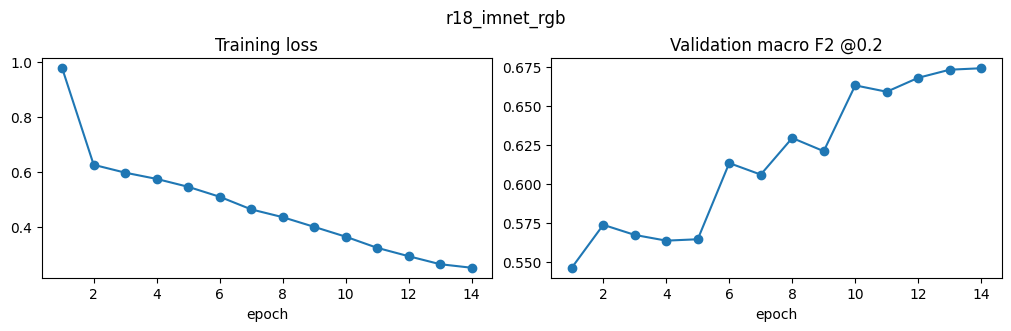

In [ ]:
NAME = "r18_imnet_rgb"

h = json.load(open(f"{RUNS}/{NAME}_history.json"))
s = json.load(open(f"{RUNS}/{NAME}_settings.json"))
print(f"{NAME}: best epoch {s.get('best_epoch')} | {s.get('n_params', 0)/1e6:.1f}M params | "
      f"{s.get('train_s_per_epoch', 0):.0f} s/epoch | GPU {s.get('gpu', '?')}")
print(f"{'epoch':>5} {'res':>5} {'train loss':>11} {'val macro F2':>13} {'sec':>6}")
for e in h:
    mark = "  <- best" if e["epoch"] == s.get("best_epoch") else ""
    print(f"{e['epoch']:>5} {e.get('res', ''):>5} {e['train_loss']:>11.4f} {e['val_macro_f2_fixed']:>13.4f} {e.get('train_s', 0):>6.0f}{mark}")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
ep = [e["epoch"] for e in h]
ax[0].plot(ep, [e["train_loss"] for e in h], marker="o"); ax[0].set(title="Training loss", xlabel="epoch")
ax[1].plot(ep, [e["val_macro_f2_fixed"] for e in h], marker="o"); ax[1].set(title="Validation macro F2 @0.2", xlabel="epoch")
fig.suptitle(NAME); plt.show()

## 9. When you're done
Everything is already on Drive. To stop spending compute units, use **Runtime → Disconnect and delete runtime**, or run the cell below.

**Next:** in the evaluation notebook, change `RUNS` to `f"{DRIVE_DIR}/ladder_runs_v2"` and rerun it from the top.

In [ ]:
print("finished runs:", finished())
from google.colab import runtime
runtime.unassign()                     # shuts the GPU session down

finished runs: ['effb0_imnet_rgb', 'effb0_imnet_rgb_256', 'r18_imnet_rgb', 'r18_imnet_rgb_256', 'r18_imnet_rgb_256_s1', 'r18_imnet_rgb_256_s2', 'r18_imnet_rgb_avgmax', 'r18_imnet_rgb_lr0.0003', 'r18_imnet_rgb_nobal', 'r18_imnet_rgb_prog3', 'r18_imnet_rgb_prog3_s1', 'r18_imnet_rgb_prog3_s2', 'r18_imnet_rgb_s1', 'r18_imnet_rgb_s2', 'r18_imnet_rgbn', 'r18_none_rgb', 'r18_none_rgb_e28', 'r18_none_rgb_s1', 'r18_none_rgb_s2', 'r18_none_rgbn', 'r18_none_rgbn_e28', 'r18_s2_rgb', 'r18_s2_rgb_prog3_s2rgb', 'r18_s2_rgb_s2rgb', 'r18_s2_rgb_s2rgb_s1', 'r18_s2_rgb_s2rgb_s2', 'r18_s2_rgb_s2rgb_s2norm', 'r18_s2_rgbn', 'r34_imnet_rgb', 'r34_imnet_rgb_256', 'r34_imnet_rgb_256_s1', 'r34_imnet_rgb_256_s2', 'r34_imnet_rgb_s1', 'r34_imnet_rgb_s2', 'scratch_none_rgb', 'scratch_none_rgb_e28', 'scratch_none_rgbnv', 'scratch_none_rgbnv_e28']


row 1: chip 35044 (train_35044), label slash_burn, found
row 2: chip 26714 (train_26714), label slash_burn, missed
row 3: chip 26020 (train_26020), label selective_logging, found
row 4: chip 997 (train_997), label selective_logging, missed


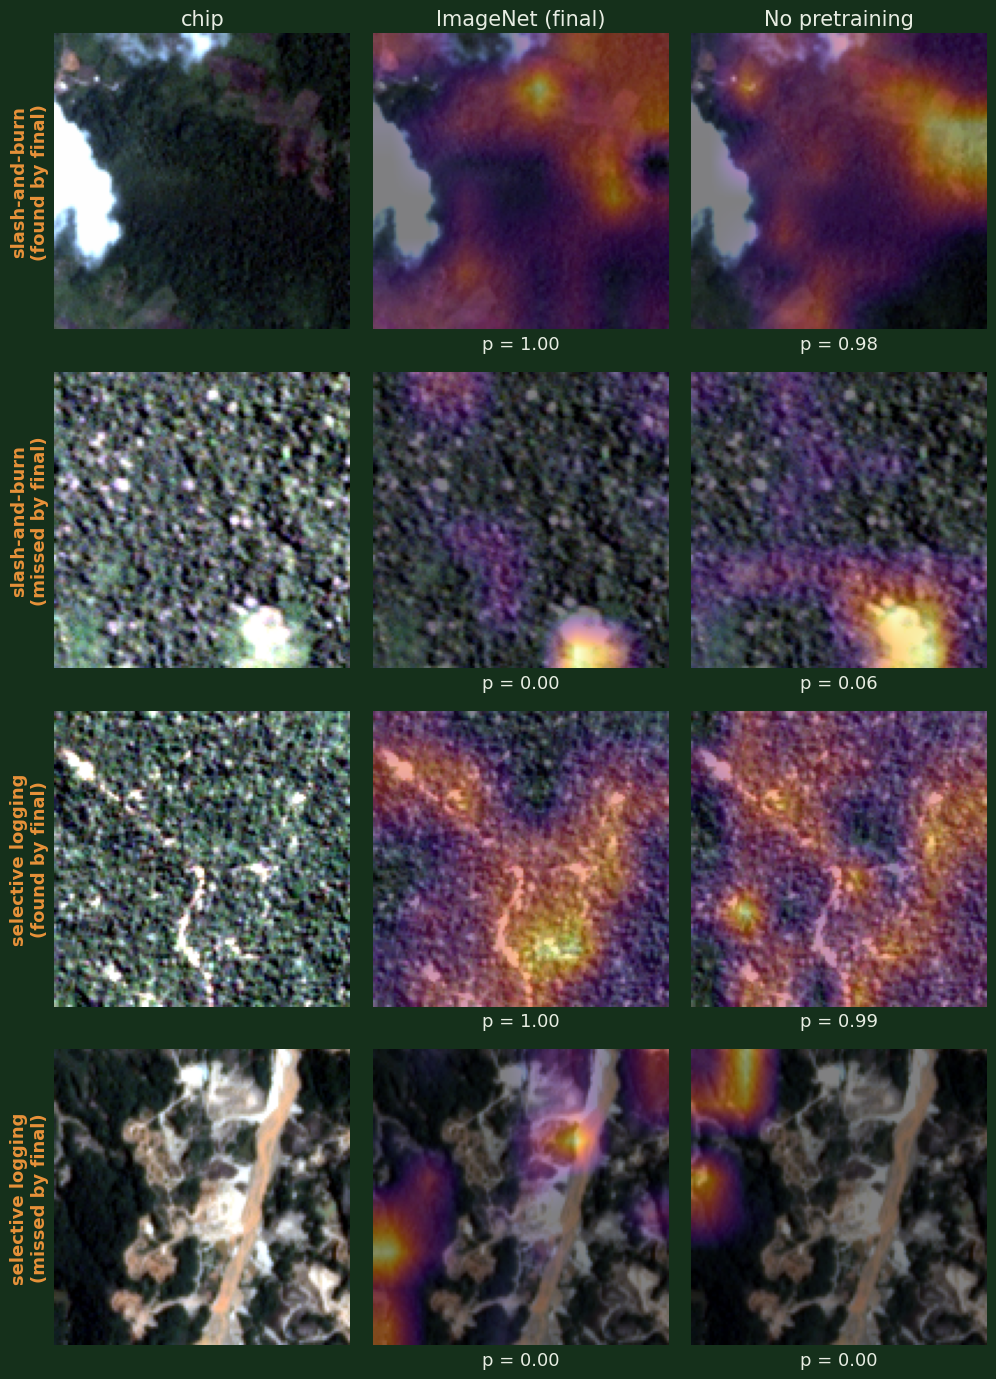

In [ ]:
# ===== Grad-CAM: where do the models look when they predict a deforestation label?
# Add to Training notebook v2 after sections 1-4 (it needs ROOT128, RUNS and the `rl` module from section 4).
# A CPU runtime is enough. Compares the final model (ImageNet) with the untrained ResNet-18 on the SAME test chips.
#
# How Grad-CAM works: take the model's score (logit) for one label, backpropagate it to a convolutional layer,
# average the gradients of each feature map into one weight per map, and add up the maps with those weights.
# Bright areas are the parts of the chip that pushed the score UP. We use layer3 (an 8 x 8 grid at 128 px)
# because layer4 is only 4 x 4 at 128 px, which gives 16 big blocks.
import os, json, numpy as np, torch, torch.nn.functional as F
import matplotlib as mpl, matplotlib.pyplot as plt
os.environ["LADDER_OFFLINE_TEST"] = "1"                 # build the network without downloading weights (we load ours)

MODELS = {"ImageNet (final)": "r18_imnet_rgb", "No pretraining": "r18_none_rgb"}
CAM_LABELS = ["slash_burn", "selective_logging"]        # one row group per label
N_HIT, N_MISS = 1, 1                                    # per label: most confident correct finds, most confident misses
CHIPS = None                                            # or a list of (chip index, label) to choose chips yourself

DECK = dict(bg="#15301B", text="#E8EDE3", muted="#A9BBA3", moss="#97BC62", orange="#E8923A")
mpl.rcParams.update({"figure.facecolor": DECK["bg"], "axes.facecolor": DECK["bg"], "savefig.facecolor": DECK["bg"],
                     "text.color": DECK["text"], "font.size": 14, "savefig.dpi": 200, "savefig.bbox": "tight"})
NICE = {"slash_burn": "slash-and-burn", "selective_logging": "selective logging",
        "artisinal_mine": "artisanal mine", "conventional_mine": "conventional mine"}

c128 = f"{ROOT128}/cache"
labels_ = json.load(open(f"{c128}/labels.json"))
Y_ = np.load(f"{c128}/Y.npy")
st_ = np.load(f"{c128}/stats.npz")
X_ = np.load(f"{c128}/X.npy", mmap_mode="r")
names_ = json.load(open(f"{c128}/names.json"))

def load_model(run):
    """Rebuild a trained run from its settings file and load its best weights."""
    meta = json.load(open(f"{RUNS}/{run}_settings.json"))
    s = rl.full_settings({k: meta[k] for k in rl.DEFAULTS if k in meta})
    m = rl.build_model(s, len(labels_))
    m.load_state_dict(torch.load(f"{RUNS}/{run}.pt", map_location="cpu"))
    return m.eval(), s

def gradcam(model, s, i, label):
    """Heatmap (128 x 128, 0-1) and probability for one chip and one land label."""
    ch = s["chans"]
    x = torch.tensor(np.asarray(X_[i][ch], dtype=np.float32))[None]
    x = (x - torch.tensor(st_["mean"][ch]).view(1, -1, 1, 1)) / torch.tensor(st_["std"][ch]).view(1, -1, 1, 1)
    acts = {}
    layer = model.features[6]                            # ResNet: conv1, bn1, relu, maxpool, layer1, layer2, LAYER3, layer4
    h = layer.register_forward_hook(lambda mod, inp, out: acts.__setitem__("a", out))
    logit = model(x)[0, labels_.index(label)]
    h.remove()
    A = acts["a"]
    g = torch.autograd.grad(logit, A)[0]                 # gradient of the label's score w.r.t. layer3's maps
    cam = F.relu((g.mean((2, 3), keepdim=True) * A).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach().numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam, float(torch.sigmoid(logit.detach()))

def natural_rgb(i, lo=2, hi=98):
    img = np.transpose(np.asarray(X_[i][:3], dtype=np.float32), (1, 2, 0))
    out = np.empty_like(img)
    for c in range(3):
        a, b = np.percentile(img[..., c], [lo, hi]); out[..., c] = np.clip((img[..., c] - a) / (b - a + 1e-6), 0, 1)
    return out ** 0.9

models = {k: load_model(r) for k, r in MODELS.items()}

# Pick chips from the FINAL model's saved test probabilities (no thresholds needed):
#   hit  = a chip WITH the label that the final model gave its highest probabilities
#   miss = a chip WITH the label that the final model gave its lowest probabilities
if CHIPS is None:
    d = np.load(f"{RUNS}/{list(MODELS.values())[0]}_probs.npz")
    tp, ty, tidx = d["test_probs"], d["test_y"], d["test_idx"]
    CHIPS = []
    for l in CAM_LABELS:
        j = labels_.index(l)
        pos = np.where(ty[:, j] == 1)[0]
        order = pos[np.argsort(-tp[pos, j])]
        CHIPS += [(int(tidx[k]), l, "found") for k in order[:N_HIT]]
        CHIPS += [(int(tidx[k]), l, "missed") for k in order[::-1][:N_MISS]]
else:
    CHIPS = [(i, l, "") for i, l in CHIPS]

cols = 1 + len(models)
fig, axes = plt.subplots(len(CHIPS), cols, figsize=(3.4 * cols, 3.5 * len(CHIPS)), squeeze=False)
for r, (i, l, kind) in enumerate(CHIPS):
    rgb = natural_rgb(i)
    axes[r, 0].imshow(rgb)
    axes[r, 0].set_ylabel(f"{NICE.get(l, l)}\n({kind} by final)" if kind else NICE.get(l, l), fontsize=13,
                          color=DECK["orange"], fontweight="bold")
    for c, (mname, (m, s)) in enumerate(models.items(), start=1):
        cam, p = gradcam(m, s, i, l)
        axes[r, c].imshow(rgb)
        axes[r, c].imshow(cam, cmap="inferno", alpha=0.5, vmin=0, vmax=1)
        axes[r, c].set_xlabel(f"p = {p:.2f}", fontsize=13, color=DECK["text"])
        if r == 0: axes[r, c].set_title(mname, fontsize=15, color=DECK["text"])
    if r == 0: axes[r, 0].set_title("chip", fontsize=15, color=DECK["text"])
    for ax in axes[r]:
        ax.set_xticks([]); ax.set_yticks([])
        for sp_ in ax.spines.values(): sp_.set_visible(False)
    print(f"row {r + 1}: chip {i} ({names_[i]}), label {l}, {kind}")
fig.tight_layout()
os.makedirs(f"{RUNS}/eval", exist_ok=True)
fig.savefig(f"{RUNS}/eval/deck_gradcam.png"); plt.show()